# Handling Errors in Graphs

In [24]:
from typing import TypedDict, Optional, NotRequired, Annotated
from operator import add
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver
import random
import json

## Define the graph (introduce failure in billing_queue)

In [25]:
class TicketState(TypedDict):
    ticket_id: str
    ticket_content: str
    assigned_queue: NotRequired[Optional[str]]
    processed_by: NotRequired[Optional[str]]
    status: NotRequired[Optional[str]]
    audit_logs: Annotated[list[str], add]

In [26]:
def classify_ticket(state: TicketState): 
    ticket_content = state['ticket_content']    
    is_billing = any(keyword in ticket_content for keyword in ['bill', 'refund'])
    assigned_queue = 'billing' if is_billing else 'general'

    log_entry = f'Auto-classified into {assigned_queue} queue'
    audit_logs = [log_entry]
    
    return {'assigned_queue': assigned_queue, 'audit_logs': audit_logs}

def billing_queue(state: TicketState):
    ### Fail Always
    if True:
        raise ConnectionError('Billing Queue Down')
        
    processed_by = random.choice(['Adam', 'Bill', 'Catherine'])
    status = random.choice(['REFUND_ISSUED', 'QUESTION_ANSWERED', 'RE-ROUTE'])
    
    original_queue = assigned_queue = state['assigned_queue']
    
    log_entry = f'{original_queue}: {status} by {processed_by}'    
    if status  == 'RE-ROUTE':
        assigned_queue = 'general'
        log_entry = f'{original_queue}: {status} to {assigned_queue} by {processed_by}'
    audit_logs = [log_entry]
    
    return {
        'processed_by': processed_by, 
        'status': status, 
        'assigned_queue': assigned_queue,
        'audit_logs': audit_logs,
    }

def general_queue(state: TicketState):
    processed_by = random.choice(['David', 'Elizabeth', 'Florence'])
    status = random.choice(['RESOLVED', 'REQUESTED_CLARIFICATION', 'RE-ROUTE'])
    
    original_queue = assigned_queue = state['assigned_queue']
    
    log_entry = f'{original_queue}: {status} by {processed_by}'    
    if status  == 'RE-ROUTE':
        assigned_queue = 'billing'
        log_entry = f'{original_queue}: {status} to {assigned_queue} by {processed_by}'
    audit_logs = [log_entry]
        
    return {
        'processed_by': processed_by, 
        'status': status, 
        'assigned_queue': assigned_queue,
        'audit_logs': audit_logs,
    }

def route_after_classification(state: TicketState):
    return state['assigned_queue'] # 'billing' or 'general'

def route_after_queue(state: TicketState):
    status = state['status']
    if status == 'RE-ROUTE':
        return state['assigned_queue']
    return 'goto_end'

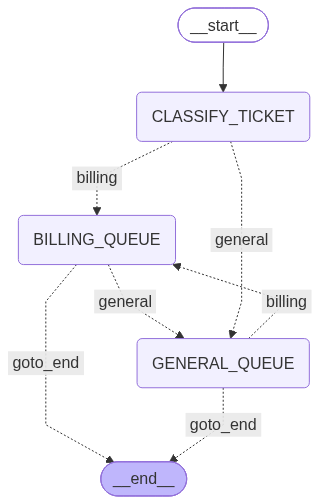

In [35]:
builder = StateGraph(TicketState)

builder.add_node('CLASSIFY_TICKET', classify_ticket)
builder.add_node('BILLING_QUEUE', billing_queue)
builder.add_node('GENERAL_QUEUE', general_queue)

builder.add_edge(START, 'CLASSIFY_TICKET')

builder.add_conditional_edges(
    'CLASSIFY_TICKET', 
    route_after_classification, 
    {
        'billing': 'BILLING_QUEUE',
        'general': 'GENERAL_QUEUE'
    }
)

builder.add_conditional_edges(
    'BILLING_QUEUE', 
    route_after_queue, 
    {
        'general': 'GENERAL_QUEUE',
        'goto_end': END,
    }
)

builder.add_conditional_edges(
    'GENERAL_QUEUE', 
    route_after_queue, 
    {
        'billing': 'BILLING_QUEUE',
        'goto_end': END,
    }
)

checkpointer = InMemorySaver()

graph = builder.compile(checkpointer=checkpointer)
graph

In [36]:
new_ticket = {
    'ticket_id': 'INC125126',
    'ticket_content': 'I was double charged on my laptop purchase. Please issue me a refund.',
    'audit_logs': ['Submitted by John Doe']
}

config = {"configurable": {"thread_id": "request_1"}}

try:
    graph.invoke(new_ticket, config=config)
except Exception as e:
    print(e)

Billing Queue Down


In [38]:
graph.get_state(config=config)

StateSnapshot(values={'ticket_id': 'INC125126', 'ticket_content': 'I was double charged on my laptop purchase. Please issue me a refund.', 'assigned_queue': 'billing', 'audit_logs': ['Submitted by John Doe', 'Auto-classified into billing queue']}, next=('BILLING_QUEUE',), config={'configurable': {'thread_id': 'request_1', 'checkpoint_ns': '', 'checkpoint_id': '1f1cd14d-61bd-684c-8001-9fefd88bb63d'}}, metadata={'source': 'loop', 'step': 1, 'parents': {}}, created_at='2026-10-21T06:01:20.038495+00:00', parent_config={'configurable': {'thread_id': 'request_1', 'checkpoint_ns': '', 'checkpoint_id': '1f1cd14d-61bb-61fa-8000-3218535550a9'}}, tasks=(PregelTask(id='679b8d79-ce67-0bdf-7c79-a8256fa958a0', name='BILLING_QUEUE', path=('__pregel_pull', 'BILLING_QUEUE'), error="ConnectionError('Billing Queue Down')", interrupts=(), state=None, result=None),), interrupts=())

### Add Retry Policy

In [39]:
from langgraph.types import RetryPolicy

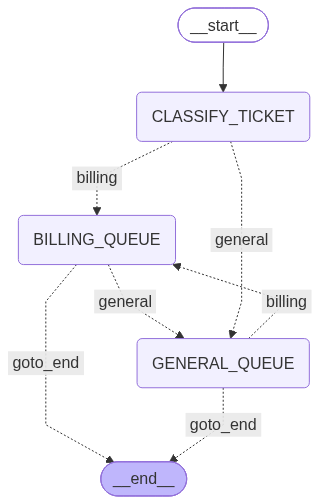

In [46]:
builder = StateGraph(TicketState)

builder.add_node('CLASSIFY_TICKET', classify_ticket)

# Configure RetryPolicy on billing queue
builder.add_node('BILLING_QUEUE', 
                 billing_queue, 
                 retry_policy=RetryPolicy(max_attempts=3)
)

builder.add_node('GENERAL_QUEUE', general_queue)

builder.add_edge(START, 'CLASSIFY_TICKET')

builder.add_conditional_edges(
    'CLASSIFY_TICKET', 
    route_after_classification, 
    {
        'billing': 'BILLING_QUEUE',
        'general': 'GENERAL_QUEUE'
    }
)

builder.add_conditional_edges(
    'BILLING_QUEUE', 
    route_after_queue, 
    {
        'general': 'GENERAL_QUEUE',
        'goto_end': END,
    }
)

builder.add_conditional_edges(
    'GENERAL_QUEUE', 
    route_after_queue, 
    {
        'billing': 'BILLING_QUEUE',
        'goto_end': END,
    }
)

checkpointer = InMemorySaver()

graph = builder.compile(checkpointer=checkpointer)
graph

In [47]:
new_ticket = {
    'ticket_id': 'INC125126',
    'ticket_content': 'I was double charged on my laptop purchase. Please issue me a refund.',
    'audit_logs': ['Submitted by John Doe']
}

config = {"configurable": {"thread_id": "request_1"}}

try:
    graph.invoke(new_ticket, config=config)
except Exception as e:
    print(e)

Billing Queue Down


### Create an API Simulator with intermittent failures

In [53]:
def api_simulator():
    yield ConnectionError('API Call Down - 1st Attempt')
    yield ConnectionError('API Call Down - 2nd Attempt')
    yield {'payload': 'data'}

In [61]:
api_call = api_simulator()
next(api_call)

ConnectionError('API Call Down - 1st Attempt')

In [62]:
next(api_call)

ConnectionError('API Call Down - 2nd Attempt')

In [63]:
next(api_call)

{'payload': 'data'}

In [65]:
# next(api_call)

### Configure API call to succeed on 3rd attempt

In [71]:
api_call = api_simulator()

In [72]:
def billing_queue(state: TicketState):
    ### Fail conditionally
    result = next(api_call)
    if isinstance(result, Exception):
        raise result    
        
    processed_by = random.choice(['Adam', 'Bill', 'Catherine'])
    status = random.choice(['REFUND_ISSUED', 'QUESTION_ANSWERED', 'RE-ROUTE'])
    
    original_queue = assigned_queue = state['assigned_queue']
    
    log_entry = f'{original_queue}: {status} by {processed_by}'    
    if status  == 'RE-ROUTE':
        assigned_queue = 'general'
        log_entry = f'{original_queue}: {status} to {assigned_queue} by {processed_by}'
    audit_logs = [log_entry]
    
    return {
        'processed_by': processed_by, 
        'status': status, 
        'assigned_queue': assigned_queue,
        'audit_logs': audit_logs,
    }

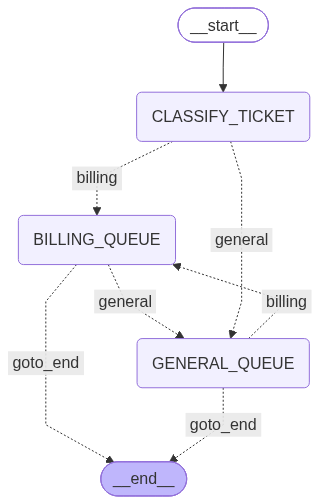

In [73]:
builder = StateGraph(TicketState)

builder.add_node('CLASSIFY_TICKET', classify_ticket)

# Configure RetryPolicy on billing queue
builder.add_node('BILLING_QUEUE', 
                 billing_queue, 
                 retry_policy=RetryPolicy(max_attempts=3)
)

builder.add_node('GENERAL_QUEUE', general_queue)

builder.add_edge(START, 'CLASSIFY_TICKET')

builder.add_conditional_edges(
    'CLASSIFY_TICKET', 
    route_after_classification, 
    {
        'billing': 'BILLING_QUEUE',
        'general': 'GENERAL_QUEUE'
    }
)

builder.add_conditional_edges(
    'BILLING_QUEUE', 
    route_after_queue, 
    {
        'general': 'GENERAL_QUEUE',
        'goto_end': END,
    }
)

builder.add_conditional_edges(
    'GENERAL_QUEUE', 
    route_after_queue, 
    {
        'billing': 'BILLING_QUEUE',
        'goto_end': END,
    }
)

checkpointer = InMemorySaver()

graph = builder.compile(checkpointer=checkpointer)
graph

In [74]:
new_ticket = {
    'ticket_id': 'INC125126',
    'ticket_content': 'I was double charged on my laptop purchase. Please issue me a refund.',
    'audit_logs': ['Submitted by John Doe']
}

config = {"configurable": {"thread_id": "request_1"}}

graph.invoke(new_ticket, config=config)

{'ticket_id': 'INC125126',
 'ticket_content': 'I was double charged on my laptop purchase. Please issue me a refund.',
 'assigned_queue': 'billing',
 'processed_by': 'Catherine',
 'status': 'QUESTION_ANSWERED',
 'audit_logs': ['Submitted by John Doe',
  'Auto-classified into billing queue',
  'billing: QUESTION_ANSWERED by Catherine']}

### Configure node with Error handler if max_retries exhaust

In [92]:
def external_api_call_that_always_fails():
    print('Invoking API - Failing')
    raise ConnectionError('API is down')

In [93]:
def billing_queue(state: TicketState):
    ### Fail always
    external_api_call_that_always_fails()
        
    processed_by = random.choice(['Adam', 'Bill', 'Catherine'])
    status = random.choice(['REFUND_ISSUED', 'QUESTION_ANSWERED', 'RE-ROUTE'])
    
    original_queue = assigned_queue = state['assigned_queue']
    
    log_entry = f'{original_queue}: {status} by {processed_by}'    
    if status  == 'RE-ROUTE':
        assigned_queue = 'general'
        log_entry = f'{original_queue}: {status} to {assigned_queue} by {processed_by}'
    audit_logs = [log_entry]
    
    return {
        'processed_by': processed_by, 
        'status': status, 
        'assigned_queue': assigned_queue,
        'audit_logs': audit_logs,
    }

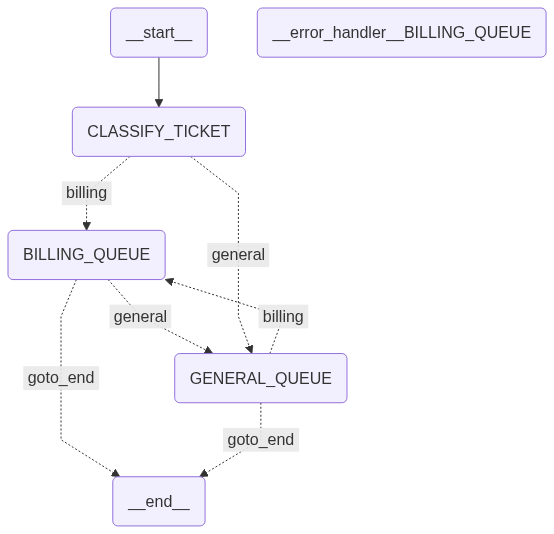

In [96]:
from langgraph.errors import NodeError
from langgraph.types import Command

builder = StateGraph(TicketState)

builder.add_node('CLASSIFY_TICKET', classify_ticket)

# define error handler for billing queue
def billing_error_handler(state: TicketState, error: NodeError):
    original_queue = state['assigned_queue'] # billing
    processed_by = 'AUTO_BILLING_ERROR_HANDLER'
    status = 'RE-ROUTE'
    assigned_queue = 'general'

    
    log_entry = f'{original_queue}: {status} to {assigned_queue} by {processed_by}'
    audit_logs = [log_entry]
    
    return Command(
        update = {
            'processed_by': processed_by, 
            'status': status, 
            'assigned_queue': assigned_queue,
            'audit_logs': audit_logs,
        },
        goto='GENERAL_QUEUE'
    )
    

# Configure error handler on billing queue
builder.add_node('BILLING_QUEUE', 
                 billing_queue, 
                 retry_policy=RetryPolicy(max_attempts=3),
                 error_handler=billing_error_handler
)

builder.add_node('GENERAL_QUEUE', general_queue)

builder.add_edge(START, 'CLASSIFY_TICKET')

builder.add_conditional_edges(
    'CLASSIFY_TICKET', 
    route_after_classification, 
    {
        'billing': 'BILLING_QUEUE',
        'general': 'GENERAL_QUEUE'
    }
)

builder.add_conditional_edges(
    'BILLING_QUEUE', 
    route_after_queue, 
    {
        'general': 'GENERAL_QUEUE',
        'goto_end': END,
    }
)

builder.add_conditional_edges(
    'GENERAL_QUEUE', 
    route_after_queue, 
    {
        'billing': 'BILLING_QUEUE',
        'goto_end': END,
    }
)

checkpointer = InMemorySaver()

graph = builder.compile(checkpointer=checkpointer)
graph

In [97]:
new_ticket = {
    'ticket_id': 'INC125126',
    'ticket_content': 'I was double charged on my laptop purchase. Please issue me a refund.',
    'audit_logs': ['Submitted by John Doe']
}

config = {"configurable": {"thread_id": "request_1"}}

graph.invoke(new_ticket, config=config)

Invoking API - Failing
Invoking API - Failing
Invoking API - Failing


{'ticket_id': 'INC125126',
 'ticket_content': 'I was double charged on my laptop purchase. Please issue me a refund.',
 'assigned_queue': 'general',
 'processed_by': 'Florence',
 'status': 'REQUESTED_CLARIFICATION',
 'audit_logs': ['Submitted by John Doe',
  'Auto-classified into billing queue',
  'billing: RE-ROUTE to general by AUTO_BILLING_ERROR_HANDLER',
  'general: REQUESTED_CLARIFICATION by Florence']}